## BÀI 4: PHÂN TÍCH ACF & PACF

**Dataset 1:** Monthly Retail Sales (`a10.csv`), 204 quan sát theo tháng (07/1991 – 06/2008).

**Đề bài:** vẽ ACF và PACF của **chuỗi đã dừng**, rồi đề xuất (p, d, q).

**Chuỗi đã dừng nhóm dùng:** `log(value)` rồi sai phân bậc 1 (**d = 1**). Đây là cách khớp với Bài 3 và Bài 5 của nhóm
(Bài 3: ADF p = 0.0002 → dừng, Bài 5: dùng log + d = 1).

**Cách đọc notebook này**
- Mục **TRẢ LỜI** = chỗ trả lời **"Câu hỏi cần trả lời"** của đề (3 câu: ACF cắt cụt ở lag nào, PACF cắt cụt ở lag nào, gợi ý ARIMA(p,d,q)).
- **Tự hỏi:**  câu **tự hỏi** khi làm đến đâu hiểu đến đó.
- **Đổi số:**  ví dụ **đổi số xem chuyện gì xảy ra** để dễ hình dung.

### 0. Thư viện và các hàm dùng chung

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["figure.dpi"] = 100

URL_A10 = "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv"


def doc_a10():
    """Ưu tiên đọc file trong repo (data/raw/a10.csv); không có thì tải từ URL.
    Thử cả 2 vị trí để notebook chạy được dù đặt ở thư mục BT_Normal hay BT_Normal/src."""
    for p in [Path("data/raw/a10.csv"), Path("../data/raw/a10.csv")]:
        if p.is_file():
            print("Đọc dữ liệu từ file cục bộ:", p)
            return pd.read_csv(p)
    print("Không thấy file cục bộ, đọc từ URL:", URL_A10)
    return pd.read_csv(URL_A10)

def kiem_dinh_adf(chuoi, ten):
    """Chạy ADF. H0: chuỗi có nghiệm đơn vị (KHÔNG dừng). p <= 0.05 => bác bỏ H0 => DỪNG."""
    r = adfuller(chuoi.dropna(), regression="c", autolag="AIC")
    dung = r[1] <= 0.05
    print(f"[{ten}]  ADF = {r[0]:.4f} | p-value = {r[1]:.4f} | số lag = {r[2]}  =>  {'DỪNG' if dung else 'KHÔNG DỪNG'}")
    return r[1]


def lag_vuot_nguong(gia_tri, n, toi_da):
    """Trả về các lag (1..toi_da) có |hệ số| vượt ngưỡng tin cậy 95% = 1.96 / sqrt(n).
    Lưu ý: gia_tri[0] là lag 0 (luôn = 1) nên vòng lặp bắt đầu từ lag 1."""
    nguong = 1.96 / np.sqrt(n)
    return [k for k in range(1, toi_da + 1) if abs(gia_tri[k]) > nguong]


def ve_acf_pacf(x, tieu_de, lags=36):
    """Vẽ ACF và PACF cạnh nhau. Vùng xanh = khoảng tin cậy 95%; đường đỏ chấm = lag 12, 24, 36 (mùa vụ)."""
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
    plot_acf(x, lags=lags, ax=ax[0])
    ax[0].set_title(f"ACF - {tieu_de}")
    plot_pacf(x, lags=lags, ax=ax[1], method="ywm")
    ax[1].set_title(f"PACF - {tieu_de}")
    for a in ax:
        for k in (12, 24, 36):
            a.axvline(k, color="red", linestyle=":", alpha=0.5)
        a.set_xlabel("Lag (tháng)")
    plt.tight_layout()
    plt.show()


def tom_tat_acf_pacf(x, ten, lags=36):
    """In các lag vượt ngưỡng và giá trị tại các lag quan trọng. Trả về (acf, pacf, n)."""
    x = x.dropna()
    n = len(x)
    a = acf(x, nlags=lags)
    p = pacf(x, nlags=lags, method="ywm")
    print(f"[{ten}]  n = {n} | ngưỡng tin cậy 95% = ±{1.96 / np.sqrt(n):.3f}")
    print("  Lag ACF  vượt ngưỡng:", lag_vuot_nguong(a, n, lags))
    print("  Lag PACF vượt ngưỡng:", lag_vuot_nguong(p, n, lags))
    bang = pd.DataFrame({"ACF": a, "PACF": p}).round(2)
    bang.index.name = "Lag"
    display(bang.loc[[1, 2, 3, 4, 5, 11, 12, 13, 24, 36]].T)
    return a, p, n


def theta_tu_rho1(rho1):
    """Ước lượng thô hệ số MA(1) từ ACF lag 1, dùng công thức rho1 = theta / (1 + theta^2).
    Giải ra: theta = (1 - sqrt(1 - 4*rho1^2)) / (2*rho1). Chỉ có nghiệm khi |rho1| < 0.5."""
    if abs(rho1) >= 0.5:
        return None
    return (1 - np.sqrt(1 - 4 * rho1 ** 2)) / (2 * rho1)

### 1. Đọc dữ liệu và đặt `date` làm chỉ số thời gian

**Tự hỏi — Vì sao phải đổi `date` thành index thời gian (kiểu datetime)?**
Vì các hàm chuỗi thời gian (`diff`, `rolling`, `resample`, ACF/PACF, mô hình ARIMA) cần biết thứ tự và khoảng cách thời gian giữa các quan sát.
Nếu `date` chỉ là chữ thì pandas không biết "tháng 2 sau tháng 1", và mô hình sẽ không hiểu tần suất để tính mùa vụ.

**Tự hỏi — Vì sao `asfreq("MS")`?** `MS` = đầu mỗi tháng. Lệnh này gán tần suất cố định cho index, và nếu thiếu tháng nào nó chèn NaN để ta phát hiện được
(ở đây không thiếu tháng nào).

In [2]:
df = doc_a10()
df["date"] = pd.to_datetime(df["date"])          # chữ -> ngày tháng
df = df.set_index("date").sort_index()           # date làm index, sắp theo thời gian
s = df["value"].asfreq("MS")                     # gán tần suất tháng

print("Số quan sát:", len(s), "| từ", s.index.min().date(), "đến", s.index.max().date())
print("Tần suất:", s.index.freq, "| số giá trị thiếu:", s.isna().sum())
s.head()

Không thấy file cục bộ, đọc từ URL: https://raw.githubusercontent.com/selva86/datasets/master/a10.csv
Số quan sát: 204 | từ 1991-07-01 đến 2008-06-01
Tần suất: <MonthBegin> | số giá trị thiếu: 0


date
1991-07-01    3.526591
1991-08-01    3.180891
1991-09-01    3.252221
1991-10-01    3.611003
1991-11-01    3.565869
Freq: MS, Name: value, dtype: float64

### 2. Chuẩn bị "chuỗi đã dừng" (nhắc lại Bài 3)

**Tự hỏi — Vì sao phải làm chuỗi dừng trước khi vẽ ACF/PACF?** ACF/PACF chỉ đọc được đúng khi chuỗi dừng. Nếu còn trend thì ACF giảm rất chậm và
che mất cấu trúc thật của chuỗi (xem Bài 1: ACF của chuỗi gốc có lag 1 = 0.92, giảm cực chậm).

**Tự hỏi — Vì sao phải `log` trước rồi mới sai phân?** Biên độ dao động của a10 tăng dần theo mức giá trị (dạng nhân). Sai phân bậc 1 chỉ loại được trend,
không loại được phần biên độ phình to. Lấy log biến phép nhân thành phép cộng: log(T × S) = log T + log S, nên biên độ đều hơn.
Thứ tự **log trước, sai phân sau** (đảo thứ tự thì ra chuỗi khác).

**Ví dụ số — Ví dụ nhỏ:** một chuỗi tăng đều 10% mỗi kỳ: 100, 110, 121, 133.1.
Sai phân thường: 10, 11, 12.1 (tăng dần, vẫn còn trend). Sai phân của log: 0.0953, 0.0953, 0.0953 (hằng số, đã ổn định).

In [3]:
vi_du = pd.Series([100, 110, 121, 133.1])
print("Sai phân thường :", vi_du.diff().dropna().round(2).tolist())
print("Sai phân của log:", np.log(vi_du).diff().dropna().round(4).tolist())

Sai phân thường : [10.0, 11.0, 12.1]
Sai phân của log: [0.0953, 0.0953, 0.0953]


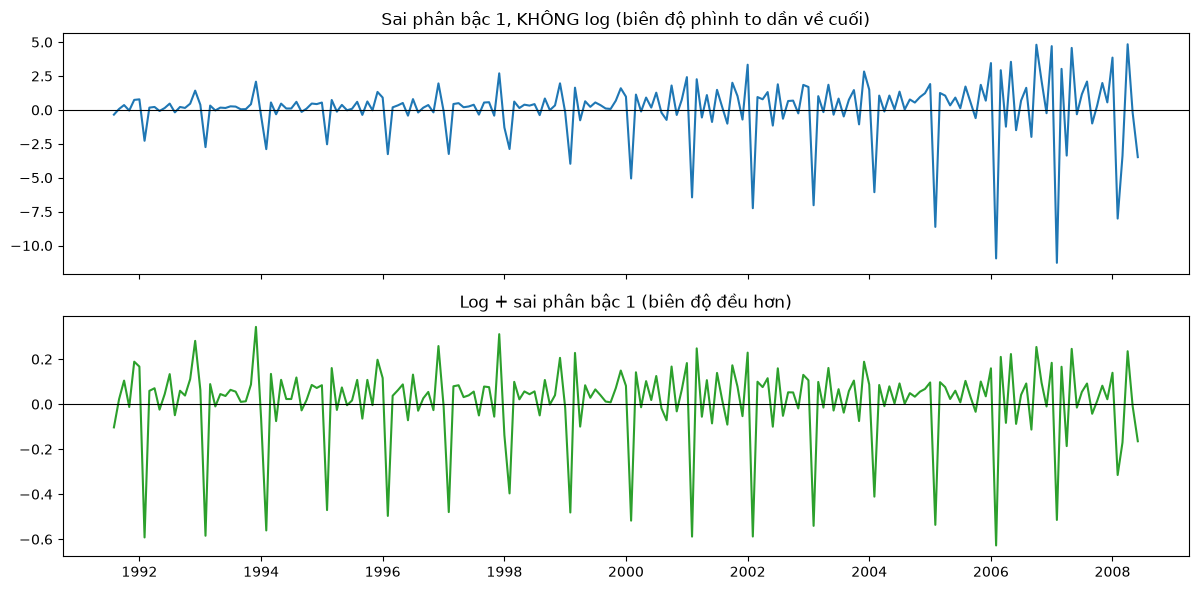

ADF - chỉ ra vì sao phải log:
[Chuỗi gốc]  ADF = 3.1452 | p-value = 1.0000 | số lag = 15  =>  KHÔNG DỪNG
[Sai phân bậc 1, không log]  ADF = -2.4952 | p-value = 0.1167 | số lag = 15  =>  KHÔNG DỪNG
[Log (chưa sai phân)]  ADF = -0.9887 | p-value = 0.7574 | số lag = 14  =>  KHÔNG DỪNG
[Log + sai phân bậc 1]  ADF = -4.5194 | p-value = 0.0002 | số lag = 13  =>  DỪNG


In [4]:
# Hai cách chuẩn bị chuỗi để so sánh: KHÔNG log và CÓ log (nhóm dùng cách có log)
d1_khong_log = s.diff().dropna()                  # sai phân bậc 1 trên chuỗi gốc
y = np.log(s)                                     # chuỗi log
y_d1 = y.diff().dropna()                          # log + sai phân bậc 1  <-- chuỗi dùng cho ACF/PACF

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(d1_khong_log); ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("Sai phân bậc 1, KHÔNG log (biên độ phình to dần về cuối)")
ax[1].plot(y_d1, color="tab:green"); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Log + sai phân bậc 1 (biên độ đều hơn)")
plt.tight_layout()
plt.show()

print("ADF - chỉ ra vì sao phải log:")
kiem_dinh_adf(s, "Chuỗi gốc")
kiem_dinh_adf(d1_khong_log, "Sai phân bậc 1, không log")
kiem_dinh_adf(y, "Log (chưa sai phân)")
p_nhom = kiem_dinh_adf(y_d1, "Log + sai phân bậc 1")
assert p_nhom <= 0.05, "Chuỗi chưa dừng, không nên vẽ ACF/PACF!"

**Nhận xét:** không log thì sai phân bậc 1 vẫn **chưa dừng** (p = 0.1167), log rồi sai phân bậc 1 thì **dừng** (p = 0.0002), nên chọn **d = 1** trên chuỗi log.
Dòng `assert` là chốt chặn: nếu chuỗi chưa dừng thì notebook dừng lại thay vì vẽ ACF/PACF sai chuỗi.

### 3. ACF và PACF đo cái gì? Ngưỡng tin cậy 95% từ đâu ra?

- **ACF(k):** tương quan giữa y_t và y_{t-k}, **bao gồm cả ảnh hưởng gián tiếp** qua các lag ở giữa.
- **PACF(k):** tương quan **trực tiếp** giữa y_t và y_{t-k} sau khi đã loại ảnh hưởng của các lag 1..k-1.
- **Vùng xanh trên biểu đồ** = ±1.96/√n. Cột nào vượt ra ngoài thì tự tương quan ở lag đó có ý nghĩa thống kê (mức 95%).
  Với 1.96 là điểm z ứng với 95% của phân phối chuẩn, n là số quan sát của chuỗi đang vẽ.

**Ví dụ số — Đổi số xem sao:** n càng lớn thì vùng xanh càng hẹp, càng dễ có nhiều lag "vượt ngưỡng". Vì vậy không nên đọc từng cột một cách máy móc.

In [5]:
for n_thu in (50, 100, 203, 1000):
    print(f"n = {n_thu:>4}  ->  ngưỡng ±{1.96 / np.sqrt(n_thu):.3f}")

n =   50  ->  ngưỡng ±0.277
n =  100  ->  ngưỡng ±0.196
n =  203  ->  ngưỡng ±0.138
n = 1000  ->  ngưỡng ±0.062


### 4. ACF và PACF của chuỗi log + sai phân bậc 1 (chuỗi nhóm dùng)

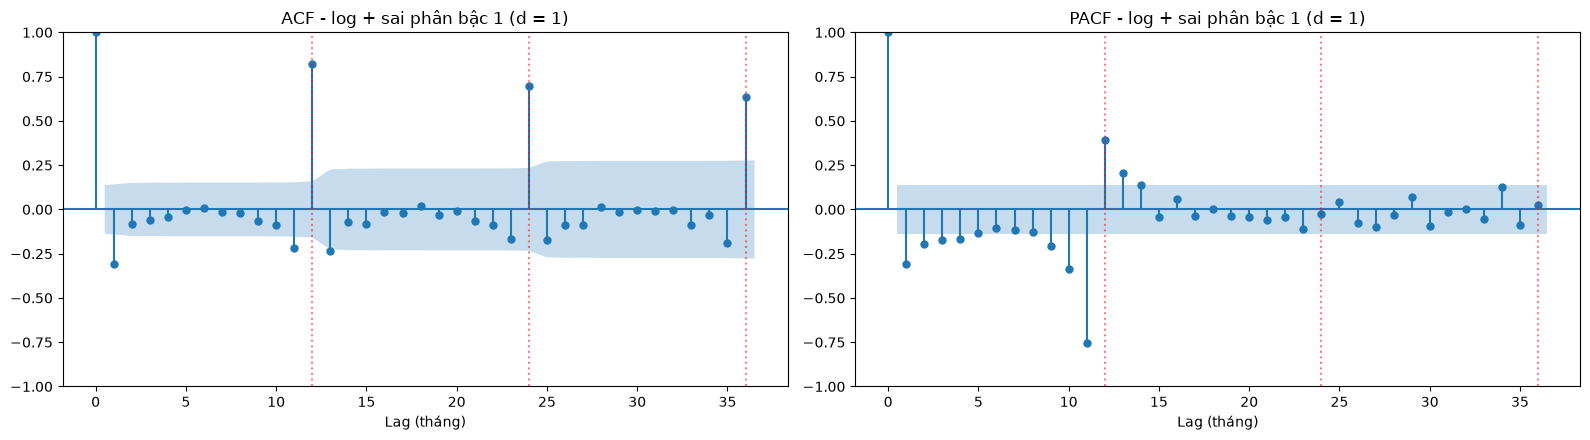

[log + d=1]  n = 203 | ngưỡng tin cậy 95% = ±0.138
  Lag ACF  vượt ngưỡng: [1, 11, 12, 13, 23, 24, 25, 35, 36]
  Lag PACF vượt ngưỡng: [1, 2, 3, 4, 9, 10, 11, 12, 13, 14]


Lag,1,2,3,4,5,11,12,13,24,36
ACF,-0.31,-0.08,-0.06,-0.04,-0.00,-0.22,0.82,-0.24,0.70,0.64
PACF,-0.31,-0.20,-0.17,-0.17,-0.13,-0.76,0.39,0.21,-0.03,0.03


In [6]:
ve_acf_pacf(y_d1, "log + sai phân bậc 1 (d = 1)")
a1, p1, n1 = tom_tat_acf_pacf(y_d1, "log + d=1")

**Đọc biểu đồ (chuỗi log + d = 1, n = 203, ngưỡng ±0.138):**
- **ACF:** lag 1 = −0.31 vượt ngưỡng, các lag 2 đến 10 đều nằm trong vùng xanh (|ACF| ≤ 0.09). Sau đó có **đỉnh rất lớn ở lag 12 (0.82), 24 (0.70), 36 (0.64)**
  cùng các lag lân cận (11, 13, 23 đến 25, 35).
- **PACF:** lag 1 đến 4 vượt ngưỡng (−0.31, −0.20, −0.17, −0.17) và **giảm dần** chứ không cắt hẳn, kèm cụm lag 9 đến 14 (lag 12 = 0.39) do mùa vụ.

**Tự hỏi — Các đỉnh ở lag 12, 24, 36 nói lên điều gì?** ADF đã báo "dừng" (p = 0.0002), nhưng ADF **không kiểm tra mùa vụ**. ACF cho thấy chuỗi vẫn còn mùa vụ chu kỳ 12 tháng:
dừng về xu hướng chưa có nghĩa là hết mùa vụ. Phần này mô hình ARIMA thuần không xử lý được, nên cần sai phân mùa vụ (D = 1, s = 12) hoặc SARIMA.

### 5. Thêm sai phân mùa vụ (D = 1, s = 12) để so sánh

`y.diff().diff(12)` nghĩa là: sai phân bậc 1 (so với tháng trước) rồi sai phân mùa vụ (so với cùng tháng năm trước).
Mất 1 + 12 = 13 quan sát đầu, nên 204 − 13 = 191 quan sát.

Số quan sát sau d=1 và D=1: 191 (= 204 - 1 - 12)
[Log + d=1 + D=1]  ADF = -4.7855 | p-value = 0.0001 | số lag = 13  =>  DỪNG


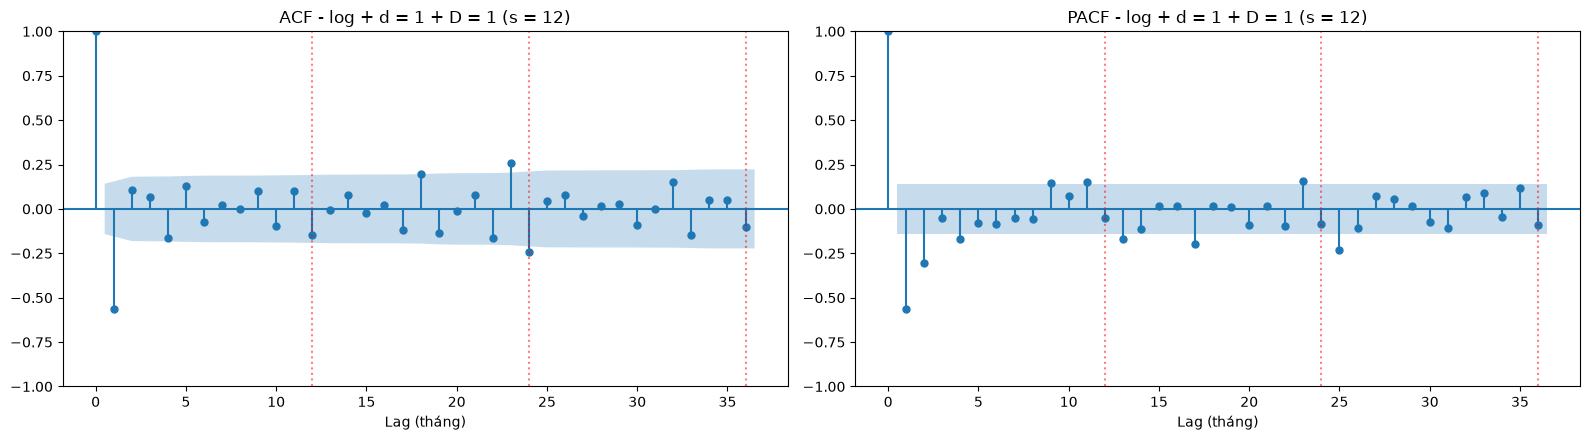

[log + d=1 + D=1]  n = 191 | ngưỡng tin cậy 95% = ±0.142
  Lag ACF  vượt ngưỡng: [1, 4, 12, 18, 22, 23, 24, 32, 33]
  Lag PACF vượt ngưỡng: [1, 2, 4, 9, 11, 13, 17, 23, 25]


Lag,1,2,3,4,5,11,12,13,24,36
ACF,-0.56,0.11,0.06,-0.16,0.13,0.10,-0.15,-0.01,-0.24,-0.10
PACF,-0.56,-0.31,-0.05,-0.17,-0.08,0.15,-0.05,-0.17,-0.09,-0.09


In [7]:
y_d1_D1 = y.diff().diff(12).dropna()
print("Số quan sát sau d=1 và D=1:", len(y_d1_D1), "(= 204 - 1 - 12)")
kiem_dinh_adf(y_d1_D1, "Log + d=1 + D=1")

ve_acf_pacf(y_d1_D1, "log + d = 1 + D = 1 (s = 12)")
a2, p2, n2 = tom_tat_acf_pacf(y_d1_D1, "log + d=1 + D=1")

In [8]:
# Bảng so sánh trước và sau khi sai phân mùa vụ
def dong(a, p, n):
    return {"n": n,
            "ACF lag 1": a[1], "ACF lag 12": a[12], "ACF lag 24": a[24],
            "PACF lag 12": p[12], "PACF lag 24": p[24],
            "Số lag ACF vượt ngưỡng (1-36)": len(lag_vuot_nguong(a, n, 36))}

so_sanh = pd.DataFrame({"log + d=1": dong(a1, p1, n1), "log + d=1 + D=1": dong(a2, p2, n2)}).T
for cot in ("n", "Số lag ACF vượt ngưỡng (1-36)"):
    so_sanh[cot] = so_sanh[cot].astype(int)      # hai cột này là số đếm nên để dạng số nguyên
display(so_sanh.round(2))

,n,ACF lag 1,ACF lag 12,ACF lag 24,PACF lag 12,PACF lag 24,Số lag ACF vượt ngưỡng (1-36)
log + d=1,203,-0.31,0.82,0.70,0.39,-0.03,9
log + d=1 + D=1,191,-0.56,-0.15,-0.24,-0.05,-0.09,9


**Nhận xét:**
- Sau khi thêm D = 1, các đỉnh khổng lồ ở lag 12, 24, 36 **biến mất** (ACF lag 12: 0.82 → −0.15; lag 24: 0.70 → −0.24; PACF lag 12: 0.39 → −0.05). Số lag ACF vượt ngưỡng vẫn là 9 (trước và sau), nhưng bản chất khác nhau: trước là cụm đỉnh mùa vụ rất lớn, sau chỉ là các lag rải rác vượt ngưỡng ở mức vừa phải.
- **ACF lag 1 = −0.56, lag 2 và lag 3 nằm trong vùng xanh** (0.11 và 0.06), nên phần không mùa vụ vẫn **cắt cụt sau lag 1**. Tuy vậy vẫn còn vài lag vượt ngưỡng ±0.142 (lag 4 = −0.16 và lag 12 = −0.15 chỉ vượt nhẹ, lag 24 = −0.24 vượt rõ hơn), nên "cắt cụt sạch" chỉ đúng gần đúng.
- **PACF:** lag 1 = −0.56, lag 2 = −0.31, rồi nhỏ dần (lag 4 = −0.17) → **giảm dần**, không cắt cụt.

### 6. Vì sao "ACF cắt cụt → MA" và "PACF cắt cụt → AR"? Mô phỏng và đổi số

Để chắc quy tắc nhận dạng, ta tự sinh chuỗi AR(1) và MA(1) bằng `ArmaProcess` rồi xem ACF/PACF lý thuyết:
- **AR(1)** `y_t = φ·y_{t-1} + ε_t`: ACF(k) = φ^k, **giảm dần** theo hàm mũ. PACF **cắt cụt sau lag 1**.
- **MA(1)** `y_t = ε_t + θ·ε_{t-1}`: ACF **cắt cụt sau lag 1** với ACF(1) = θ / (1 + θ²). PACF **giảm dần**.

Đổi φ và θ để thấy chuyện gì xảy ra.

AR(1): ACF lý thuyết các lag 1..5 theo phi (giảm dần, càng gần 1 càng chậm)


,phi=0.3,phi=0.8,phi=0.95
1,0.300,0.800,0.950
2,0.090,0.640,0.902
3,0.027,0.512,0.857
4,0.008,0.410,0.815
5,0.002,0.328,0.774


MA(1): ACF lý thuyết các lag 1..4 theo theta (chỉ lag 1 khác 0, và không bao giờ vượt 0.5)


,theta=0.3,theta=0.8,theta=1.0
1,0.275,0.488,0.5
2,0.000,0.000,0.0
3,0.000,0.000,0.0
4,0.000,0.000,0.0


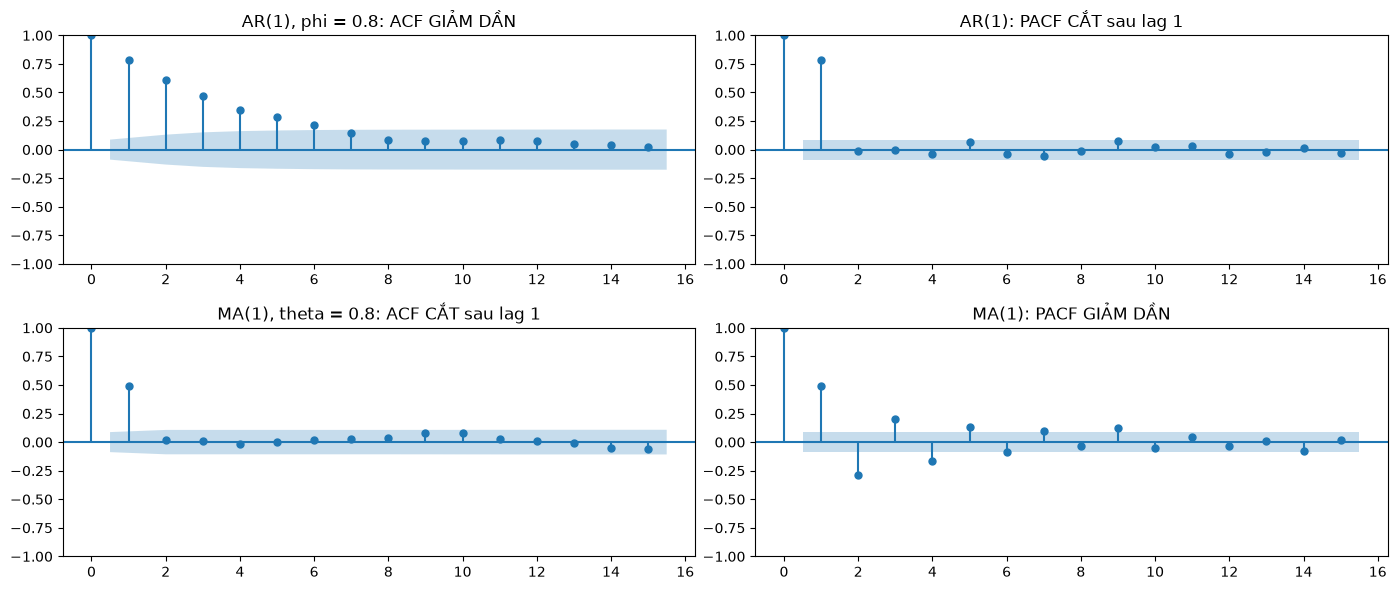

In [9]:
from statsmodels.tsa.arima_process import ArmaProcess

# Lưu ý quy ước của ArmaProcess: đa thức AR viết là [1, -phi], đa thức MA viết là [1, theta]
print("AR(1): ACF lý thuyết các lag 1..5 theo phi (giảm dần, càng gần 1 càng chậm)")
display(pd.DataFrame({f"phi={phi}": ArmaProcess([1, -phi], [1]).acf(6)[1:] for phi in (0.3, 0.8, 0.95)},
                     index=range(1, 6)).round(3))

print("MA(1): ACF lý thuyết các lag 1..4 theo theta (chỉ lag 1 khác 0, và không bao giờ vượt 0.5)")
display(pd.DataFrame({f"theta={th}": ArmaProcess([1], [1, th]).acf(5)[1:] for th in (0.3, 0.8, 1.0)},
                     index=range(1, 5)).round(3))

# Minh hoạ bằng dữ liệu mô phỏng 500 điểm: AR(1) phi=0.8 và MA(1) theta=0.8
np.random.seed(42)
ar1 = ArmaProcess([1, -0.8], [1]).generate_sample(nsample=500)
ma1 = ArmaProcess([1], [1, 0.8]).generate_sample(nsample=500)

fig, ax = plt.subplots(2, 2, figsize=(14, 6))
plot_acf(ar1, lags=15, ax=ax[0, 0]);  ax[0, 0].set_title("AR(1), phi = 0.8: ACF GIẢM DẦN")
plot_pacf(ar1, lags=15, ax=ax[0, 1], method="ywm"); ax[0, 1].set_title("AR(1): PACF CẮT sau lag 1")
plot_acf(ma1, lags=15, ax=ax[1, 0]);  ax[1, 0].set_title("MA(1), theta = 0.8: ACF CẮT sau lag 1")
plot_pacf(ma1, lags=15, ax=ax[1, 1], method="ywm"); ax[1, 1].set_title("MA(1): PACF GIẢM DẦN")
plt.tight_layout()
plt.show()

**Áp dụng vào dữ liệu:** ACF(1) của MA(1) tối đa là **0.5** (đạt khi θ = 1), vì θ / (1 + θ²) ≤ 0.5.
Hàm `theta_tu_rho1` dưới đây giải ngược công thức này để ước lượng thô θ từ ACF(1) đo được.

In [10]:
for ten, rho1 in [("log + d=1", a1[1]), ("log + d=1 + D=1", a2[1])]:
    th = theta_tu_rho1(rho1)
    if th is None:
        print(f"{ten}: ACF(1) = {rho1:.2f}, |ACF(1)| >= 0.5 nên KHÔNG thể là MA(1) thuần "
              "(cần thêm thành phần khác, ví dụ phần mùa vụ hoặc MA bậc cao hơn)")
    else:
        print(f"{ten}: ACF(1) = {rho1:.2f}  ->  theta ước lượng thô ≈ {th:.2f}")

log + d=1: ACF(1) = -0.31  ->  theta ước lượng thô ≈ -0.34
log + d=1 + D=1: ACF(1) = -0.56, |ACF(1)| >= 0.5 nên KHÔNG thể là MA(1) thuần (cần thêm thành phần khác, ví dụ phần mùa vụ hoặc MA bậc cao hơn)


**Ý nghĩa:**
- Chuỗi log + d = 1: ACF(1) = −0.31 nên θ ≈ −0.34. Hợp lý với MA(1).
- Chuỗi log + d = 1 + D = 1: ACF(1) = −0.56, **vượt giới hạn 0.5** của MA(1) thuần, nên chuỗi này không phải MA(1) thuần.
  Đây là lý do ta chỉ **đề xuất** mô hình dựa trên ACF/PACF, rồi để AIC/BIC ở Bài 5 quyết định.

### 7. Bảng quy tắc nhận dạng (p, q) từ ACF/PACF

| Mô hình | ACF | PACF |
|---|---|---|
| AR(p) | giảm dần | **cắt cụt sau lag p** |
| MA(q) | **cắt cụt sau lag q** | giảm dần |
| ARMA(p, q) | giảm dần | giảm dần |

Phần mùa vụ đọc tương tự nhưng nhìn ở các lag **12, 24, 36**: ACF cắt sau lag 12 → Q = 1, PACF cắt sau lag 12 → P = 1.

## TRẢ LỜI "CÂU HỎI CẦN TRẢ LỜI" (Bài 4)

**1. ACF cắt cụt ở lag nào?**
Chuỗi log + d = 1: phần không mùa vụ, ACF **cắt cụt sau lag 1** (lag 1 = −0.31 vượt ngưỡng ±0.138, lag 2 đến 10 nằm trong vùng xanh).
Ngoài ra còn các đỉnh rất lớn ở lag **12 (0.82), 24 (0.70), 36 (0.64)**, đó là mùa vụ chu kỳ 12 tháng chứ không phải AR/MA thông thường.
Khi thêm D = 1: ACF(1) = −0.56, lag 2 và 3 trong vùng xanh, các đỉnh mùa vụ lớn biến mất (còn lại lag 4 và 12 vượt nhẹ ngưỡng, lag 24 = −0.24 vượt rõ hơn).

**2. PACF cắt cụt ở lag nào?**
PACF **không cắt cụt rõ ràng mà giảm dần**: lag 1 đến 4 lần lượt −0.31, −0.20, −0.17, −0.17, kèm cụm lag 9 đến 14 do mùa vụ.
Khi thêm D = 1 vẫn giảm dần (−0.56, −0.31, ..., −0.17 ở lag 4). PACF giảm dần là dấu hiệu của thành phần **MA**, không phải AR thuần.

**3. Gợi ý mô hình ARIMA(p, d, q)?**
- **d = 1** (trên chuỗi đã log; ADF p = 0.0002).
- ACF cắt sau lag 1 và PACF giảm dần → **q = 1, p = 0** → **ARIMA(0,1,1)** trên log.
- Ứng viên đối chiếu: **ARIMA(1,1,1)** và **ARIMA(2,1,1)** (các ví dụ đề gợi ý); chọn theo AIC/BIC ở Bài 5.
- Vì ACF còn đỉnh mùa vụ rõ ở lag 12, 24, 36, hướng cải thiện là SARIMA, ví dụ **SARIMA(0,1,1)(0,1,1)₁₂** (D = 1, s = 12).

**Nếu thầy cô hỏi vặn:**
- *PACF lag 1 vượt ngưỡng, sao không chọn p = 1?* PACF không cắt mà giảm dần; với MA(1) thì PACF vốn giảm dần dạng mũ. Đọc ACF/PACF chỉ là gợi ý, phải so AIC/BIC (Bài 5).
- *ADF nói dừng rồi, sao ACF còn đỉnh lag 12?* ADF chỉ kiểm tra nghiệm đơn vị (xu hướng), không kiểm tra mùa vụ.
- *Không log thì sao?* Sai phân bậc 1 chưa dừng (p = 0.1167), phải d = 2 hoặc d = 1 kèm D = 1; ACF/PACF cũng ra khác, nên cả nhóm phải thống nhất một cách (nhóm chọn log + d = 1).

**Lưu ý ghép với Bài 5:** Bài 4 đề xuất ARIMA(0,1,1) trên log. Bài 5 của nhóm nên có ứng viên này trong danh sách để hai bài khớp nhau.